Prueba de extracción de texto de una imágen

In [1]:
import cv2
import easyocr
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print ("Librerias importadas correctamente")

Librerias importadas correctamente


Cargar imagen

In [16]:
ruta_imagen = Path("data/ejcorreo.png")

imagen = cv2.imread(str(ruta_imagen))

if imagen is None:
    raise FileNotFoundError(
        f"No se pudo cargar la imagen: {ruta_imagen}"
    )

print("Imagen cargada correctamente")

Imagen cargada correctamente


Mostrar la imagen a extraer el texto

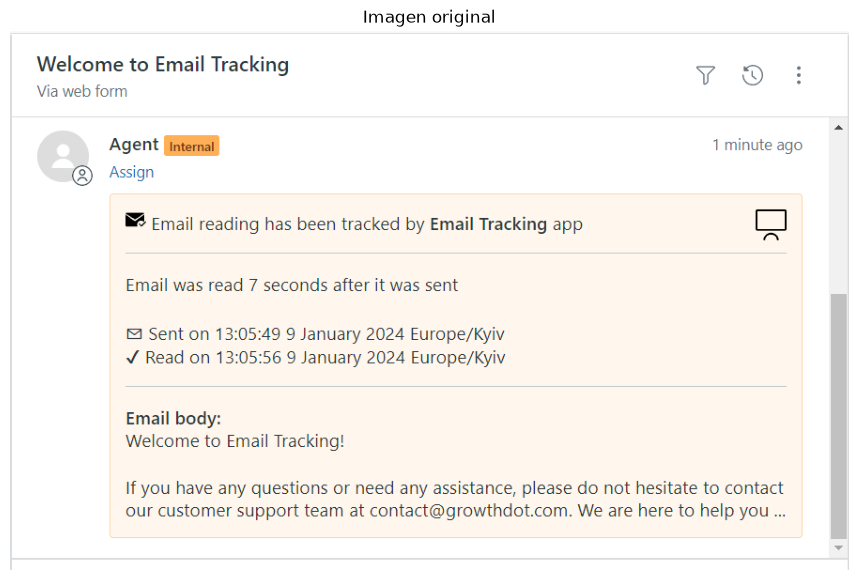

In [17]:
imagen_rgb = cv2.cvtColor(
    imagen,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))

plt.imshow(imagen_rgb)
plt.title("Imagen original")
plt.axis("off")

plt.show()

Inicialización de EasyOCR

In [11]:
# Inicializar el lector OCR
reader = easyocr.Reader(
    ['es', 'en'],
    gpu=False
)

print("Motor OCR inicializado correctamente")

Using CPU. Note: This module is much faster with a GPU.


Motor OCR inicializado correctamente


Extracción de texto

In [18]:
resultados = reader.readtext(imagen_rgb)

print("Cantidad de regiones detectadas:", len(resultados))

c:\Users\HP VICTUS\Desktop\UPS\7moCiclo\tesis\PhisLens\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Cantidad de regiones detectadas: 18


In [19]:
for resultado in resultados:

    coordenadas = resultado[0]
    texto = resultado[1]
    confianza = resultado[2]

    print("Texto reconocido:", texto)
    print("Confianza:", round(confianza, 4))
    print("-------------------------")

Texto reconocido: Welcome to Email Tracking
Confianza: 0.8144
-------------------------
Texto reconocido: 7
Confianza: 0.8079
-------------------------
Texto reconocido: 9
Confianza: 0.4565
-------------------------
Texto reconocido: Via web form
Confianza: 0.9701
-------------------------
Texto reconocido: Agent
Confianza: 1.0
-------------------------
Texto reconocido: Internal
Confianza: 0.9999
-------------------------
Texto reconocido: minute ago
Confianza: 0.9997
-------------------------
Texto reconocido: Assign
Confianza: 1.0
-------------------------
Texto reconocido: Email reading has been tracked by Email Tracking app
Confianza: 0.8604
-------------------------
Texto reconocido: Email was read
Confianza: 0.9924
-------------------------
Texto reconocido: seconds after it was sent
Confianza: 0.9933
-------------------------
Texto reconocido: Sent on 13.05.49 9 January 2024 Europe/Kyiv
Confianza: 0.9128
-------------------------
Texto reconocido: Read on 13.05.56 9 January 202

Visualizar zonas detectadas

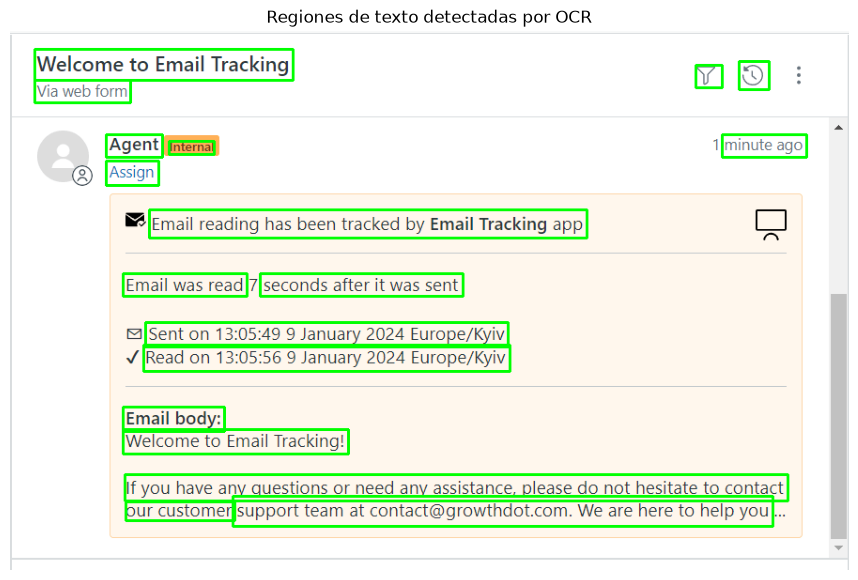

In [20]:
imagen_resultado = imagen_rgb.copy()

for resultado in resultados:

    coordenadas = resultado[0]

    puntos = np.array(
        coordenadas,
        dtype=np.int32
    )

    cv2.polylines(
        imagen_resultado,
        [puntos],
        isClosed=True,
        color=(0, 255, 0),
        thickness=2
    )

plt.figure(figsize=(12, 7))

plt.imshow(imagen_resultado)
plt.title("Regiones de texto detectadas por OCR")
plt.axis("off")

plt.show()

Texto en una sola variable

In [21]:
texto_extraido = "\n".join(
    resultado[1]
    for resultado in resultados
)

print("TEXTO EXTRAÍDO DE LA IMAGEN")
print("=" * 40)
print(texto_extraido)

TEXTO EXTRAÍDO DE LA IMAGEN
Welcome to Email Tracking
7
9
Via web form
Agent
Internal
minute ago
Assign
Email reading has been tracked by Email Tracking app
Email was read
seconds after it was sent
Sent on 13.05.49 9 January 2024 Europe/Kyiv
Read on 13.05.56 9 January 2024 Europe/Kyiv
Email body:
Welcome to Email Tracking!
If you have any questions or need any assistance; please do not hesitate to contact
our customer
support team at contact@growthdot.com. We are here to help you
